## Decision trees

![](https://drive.google.com/uc?id=13kmqLXa-3FBUJq0Q3XVOkz8TENpVTkqk)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression


from mlxtend.plotting import plot_decision_regions

In [2]:
data = load_iris()
X = pd.DataFrame(data['data'], columns=data['feature_names'])
y = data['target'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

Let's try to use a decison tree for our multiclass iris data.

In [3]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()

dt.fit(X_train, y_train)

print(accuracy_score(y_test,  dt.predict(X_test)))

0.9777777777777777


We achieved the same accuracy as with logistic regression without tuning hyperparameters.

Let's try tuning them. [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) in sklearn

In [4]:
dt_params = {'criterion':['gini', 'entropy'],
             'max_depth' : [1, 2, 5, 10, None],
             'min_samples_split' : [2, 5, 10],
             'min_samples_leaf' : [1, 2, 5, 10]
             }

clf = GridSearchCV(DecisionTreeClassifier(), dt_params,
                   cv=5, scoring='accuracy',
                   verbose=5
                   )
clf.fit(X_train, y_train)

Fitting 5 folds for each of 120 candidates, totalling 600 fits
[CV 1/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=2;, score=0.667 total time=   0.0s
[CV 2/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=2;, score=0.667 total time=   0.0s
[CV 3/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=2;, score=0.714 total time=   0.0s
[CV 4/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=2;, score=0.714 total time=   0.0s
[CV 5/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=2;, score=0.714 total time=   0.0s
[CV 1/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=5;, score=0.667 total time=   0.0s
[CV 2/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=5;, score=0.667 total time=   0.0s
[CV 3/5] END criterion=gini, max_depth=1, min_samples_leaf=1, min_samples_split=5;, score=0.714 total time=   0.0s
[CV 4/5] END crit

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [1, 2, 5, 10, None],
                         'min_samples_leaf': [1, 2, 5, 10],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy', verbose=5)

In [5]:
clf.best_params_

{'criterion': 'gini',
 'max_depth': 5,
 'min_samples_leaf': 2,
 'min_samples_split': 2}

More complicated model $→$ more hyperparameters, longer training

In [6]:
print(accuracy_score(y_test,  clf.predict(X_test)))

0.9555555555555556


Why no increase in quality?

 Compute, how many objects are classified incorrectly

In [7]:
#your code here
(y_test != clf.predict(X_test)).sum()

np.int64(2)

Even very good model may make some mistakes:



*   Outliers (particular flower is really different from the rest)
*   Errors (the flower was incorectly classified by a human)
*   Hard decision (the flower seems like several classes and the model cannot decide)



### Decision trees vs linear models

Decision tree is a new cool model, will it work better than liner regression?

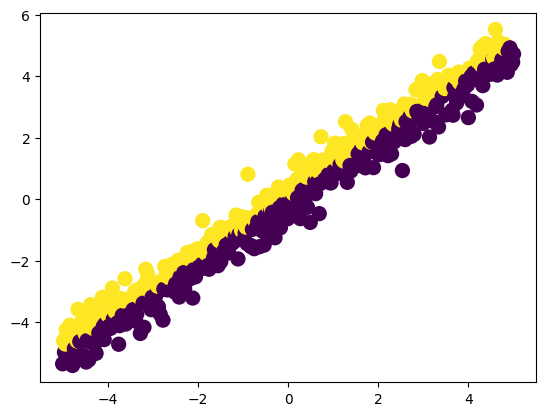

In [8]:
np.random.seed(13)
n = 500
X = np.zeros(shape=(n, 2))
X[:, 0] = np.linspace(-5, 5, 500)
X[:, 1] = X[:, 0] + 0.5 * np.random.normal(size=n)
y = (X[:, 1] > X[:, 0]).astype(int)
plt.scatter(X[:, 0], X[:, 1], s=100, c=y);

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=13
)

lr = LogisticRegression(random_state=13)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print(f"Linear model accuracy: {accuracy_score(y_pred_lr, y_test):.2f}")

Linear model accuracy: 0.99


Cool, what about a decision tree?

In [10]:
dt = DecisionTreeClassifier(random_state=13)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print(f"Decision tree accuracy: {accuracy_score(y_pred_dt, y_test):.2f}")

Decision tree accuracy: 0.86


Worse, let's plot and see the difference

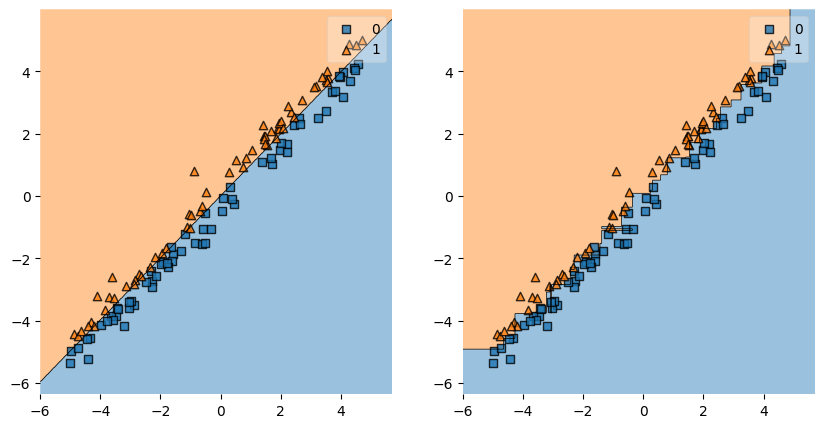

In [11]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plot_decision_regions(X_test, y_test, lr)

plt.subplot(1, 2, 2)
plot_decision_regions(X_test, y_test, dt);

The data may be separated by a strainght line - logistic regression works fine.

The line is not horizontal/vertical - so tree has some complication.

Let's check another synthetic data:

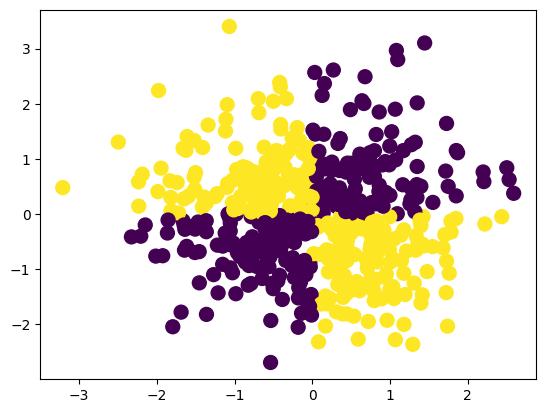

In [12]:
np.random.seed(13)
X = np.random.randn(500, 2)
y = np.logical_xor(X[:, 0] > 0, X[:, 1] > 0).astype(int)
plt.scatter(X[:, 0], X[:, 1], s=100, c=y);

**Task** Divide data into train and test, fit Logistic regression and decision tree, compute accuracy and plot them. Compare the models, which works better, why?

Linear model accuracy: 0.39
Decision tree accuracy: 0.97


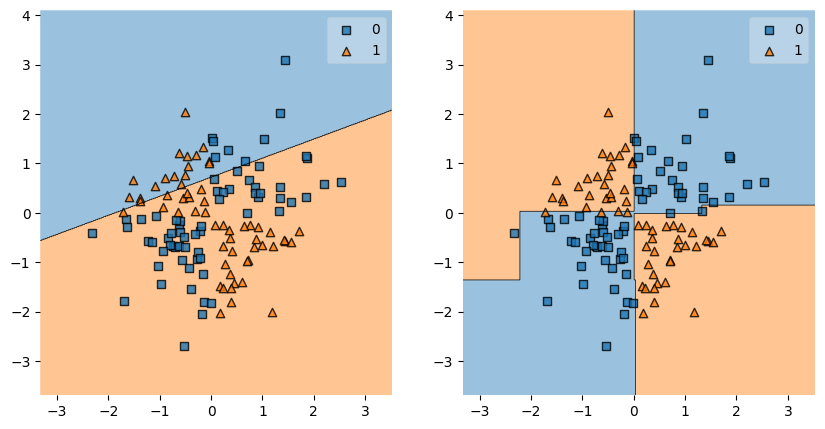

In [13]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=13
)

lr = LogisticRegression(random_state=13)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print(f"Linear model accuracy: {accuracy_score(y_pred_lr, y_test):.2f}")

dt = DecisionTreeClassifier(random_state=13)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print(f"Decision tree accuracy: {accuracy_score(y_pred_dt, y_test):.2f}")

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plot_decision_regions(X_test, y_test, lr)

plt.subplot(1, 2, 2)
plot_decision_regions(X_test, y_test, dt);

**Conclusion:** best model depends on data.

### Overfitting

Again, some synthetic data. This data is harder, because there is a significant overlap of classes.

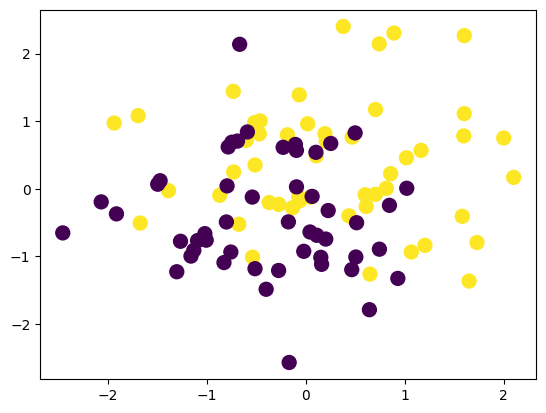

In [14]:
np.random.seed(13)
n = 100
X = np.random.normal(size=(n, 2))
X[:50, :] += 0.25
X[50:, :] -= 0.25
y = np.array([1] * 50 + [0] * 50)
plt.scatter(X[:, 0], X[:, 1], s=100, c=y);

If there are no contradicting data (same features, different target), we can achieve the best possible quality of model on train data (accuracy=1, MSE=0)

Decision tree accuracy: 1.00


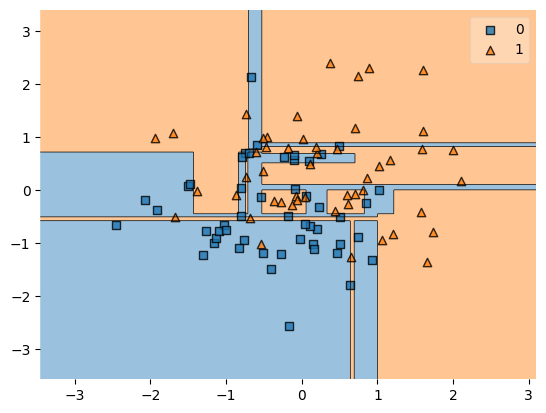

In [15]:
dt = DecisionTreeClassifier()
dt.fit(X, y)

print(f"Decision tree accuracy: {accuracy_score(y, dt.predict(X)):.2f}")

plot_decision_regions(X, y, dt);

Let's investigatre, how the model changes if we change hyperparameters

In [16]:
X.shape

(100, 2)

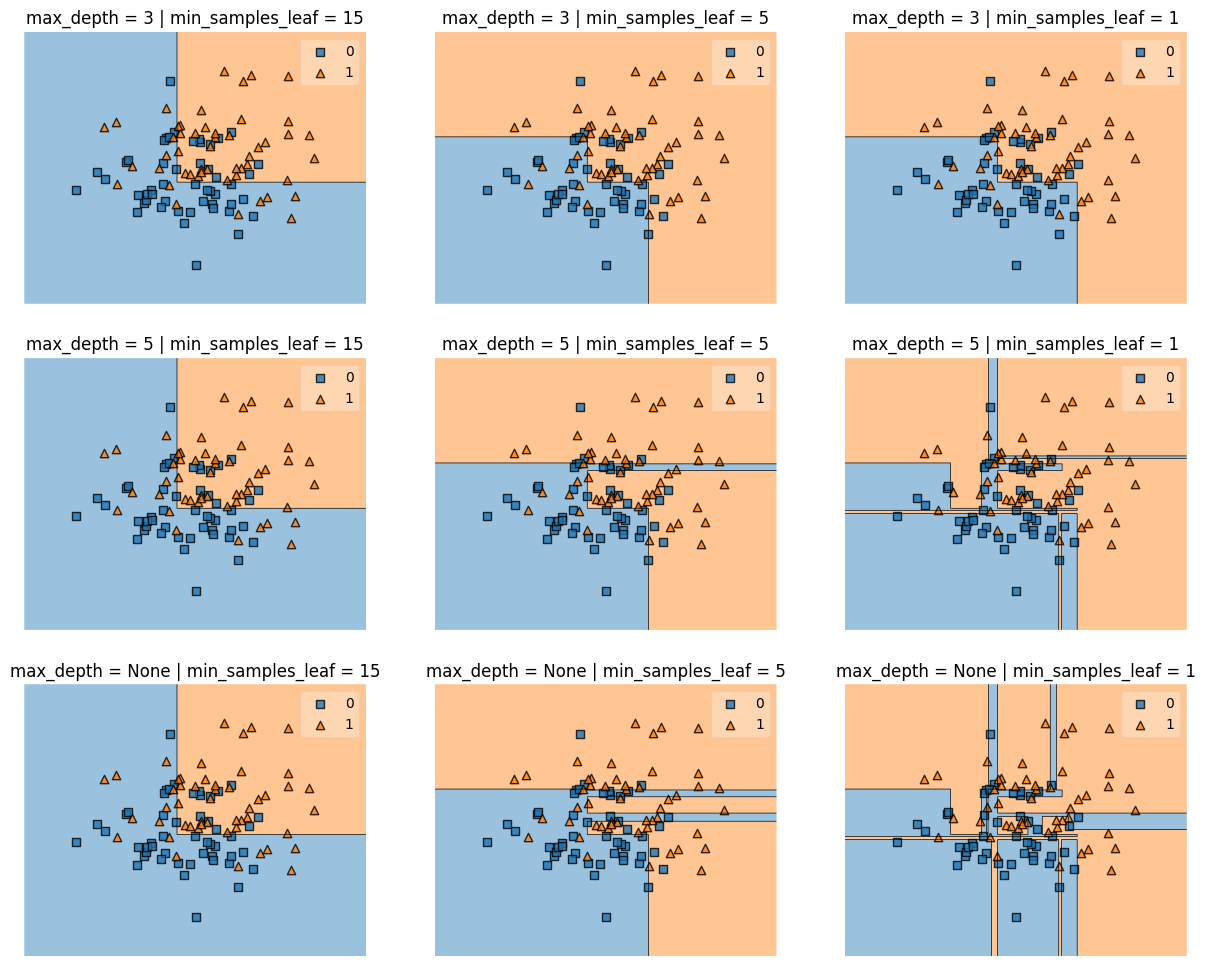

In [17]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))

for i, max_depth in enumerate([3, 5, None]):
    for j, min_samples_leaf in enumerate([15, 5, 1]):
        dt = DecisionTreeClassifier(
            max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=13
        )
        dt.fit(X, y)
        ax[i][j].set_title(
            "max_depth = {} | min_samples_leaf = {}".format(max_depth, min_samples_leaf)
        )
        ax[i][j].axis("off")
        plot_decision_regions(X, y, dt, ax=ax[i][j])

plt.show()

### Instability

Let's conduct an experiment: we will use random 90\% of our data and fit the decision tree. Will it change a lot?

**Task** Choose 90\% random samples

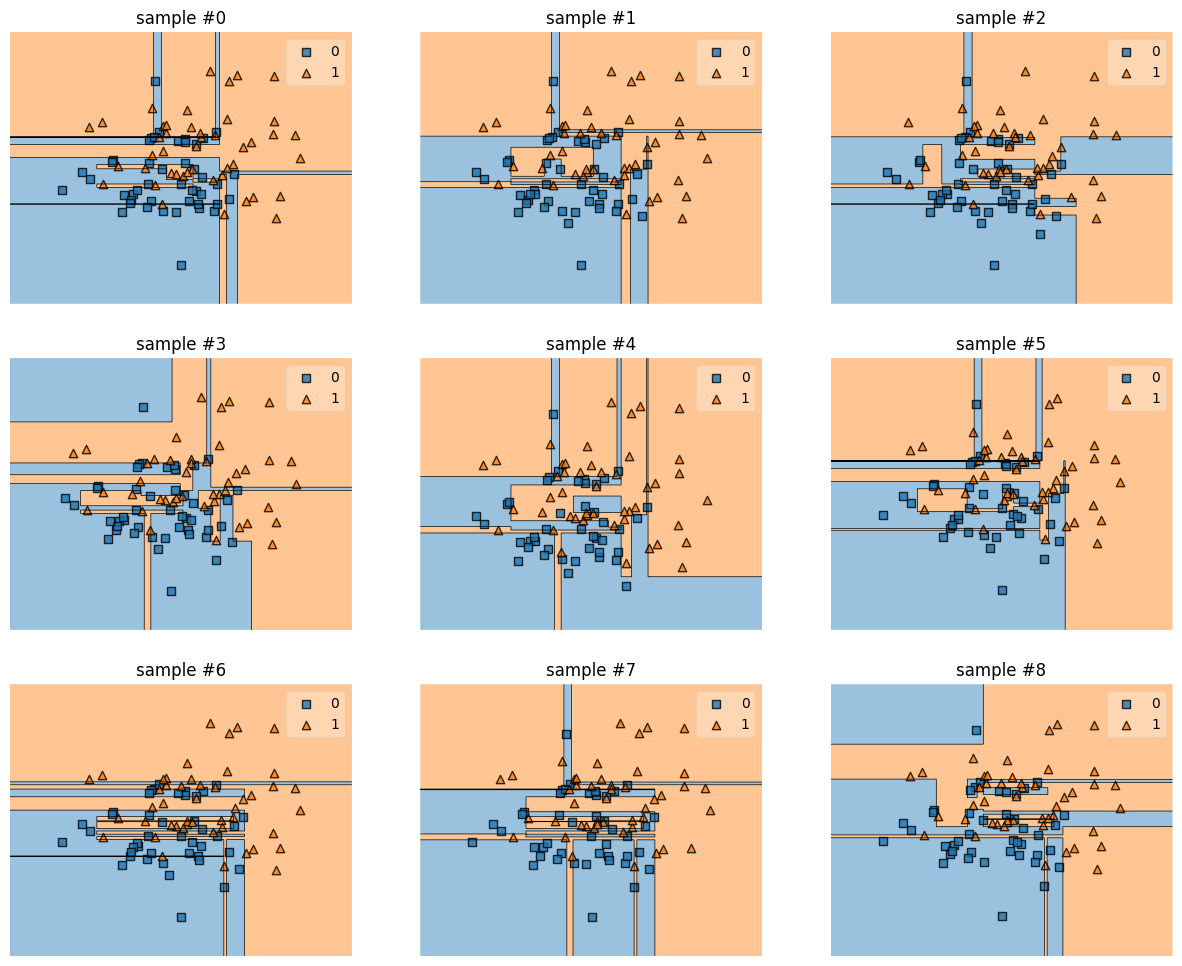

In [18]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))

for i in range(3):
    for j in range(3):
        seed_idx = 3 * i + j
        np.random.seed(seed_idx)
        dt = DecisionTreeClassifier(random_state=13)

        #Create X_part, y_part - parts of the initial sample X, y
        #May use np.random.choice to sample indices
        #your code here
        idx = np.random.choice(len(X), size=int(0.9 * len(X)), replace=False)
        X_part, y_part = X[idx], y[idx]

        dt.fit(X_part, y_part)
        ax[i][j].set_title("sample #{}".format(seed_idx))
        ax[i][j].axis("off")
        plot_decision_regions(X_part, y_part, dt, ax=ax[i][j])

plt.show()

The plot changes a lot, let's also check if logistic regression changes a lot, too:

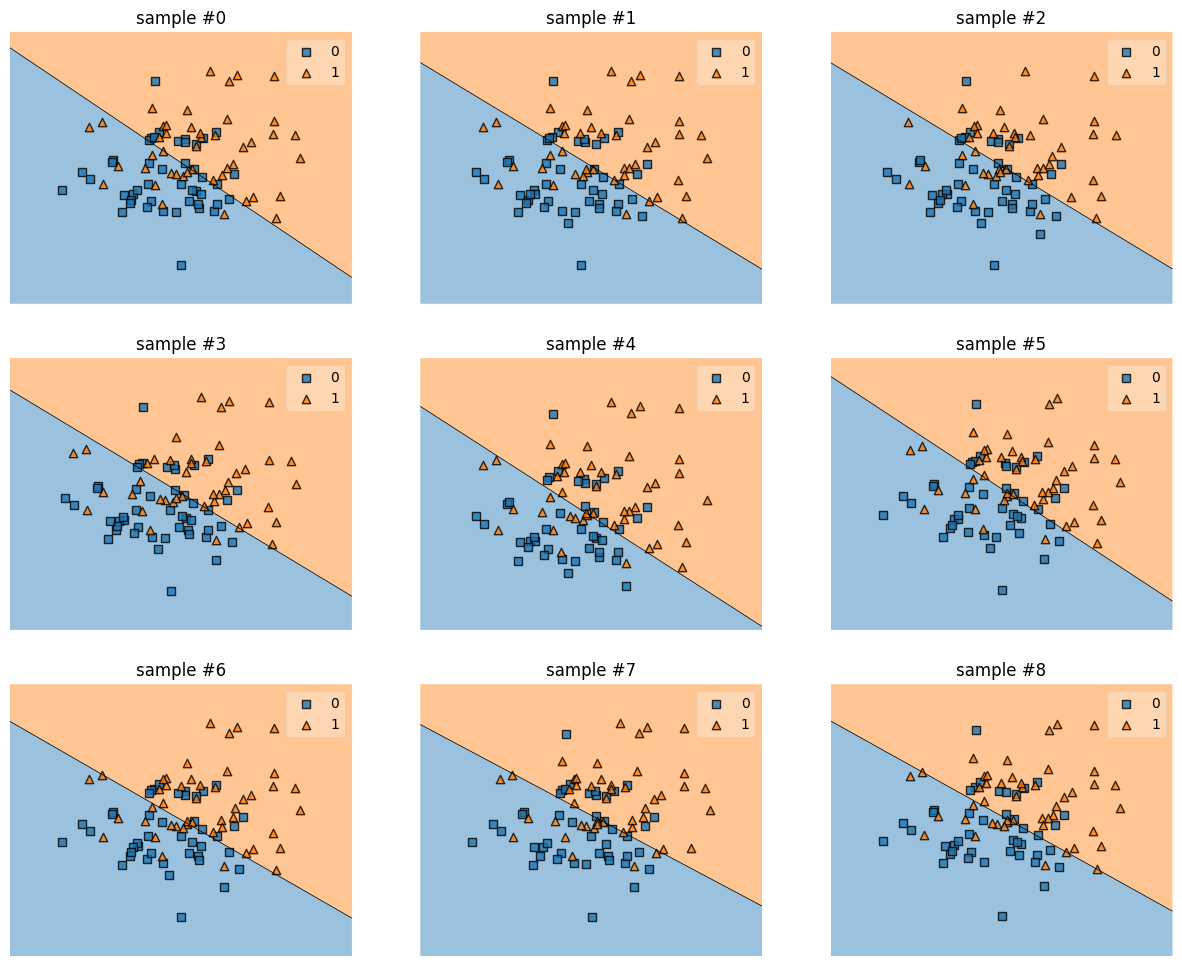

In [19]:
fig, ax = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))

for i in range(3):
    for j in range(3):
        seed_idx = 3 * i + j
        np.random.seed(seed_idx)
        dt = LogisticRegression(random_state=13)

        #Create X_part, y_part - parts of the initial sample X, y
        #May use np.random.choice to sample indices
        #your code here
        idx = np.random.choice(len(X), size=int(0.9 * len(X)), replace=False)
        X_part, y_part = X[idx], y[idx]

        dt.fit(X_part, y_part)
        ax[i][j].set_title("sample #{}".format(seed_idx))
        ax[i][j].axis("off")
        plot_decision_regions(X_part, y_part, dt, ax=ax[i][j])

plt.show()

### Visualization

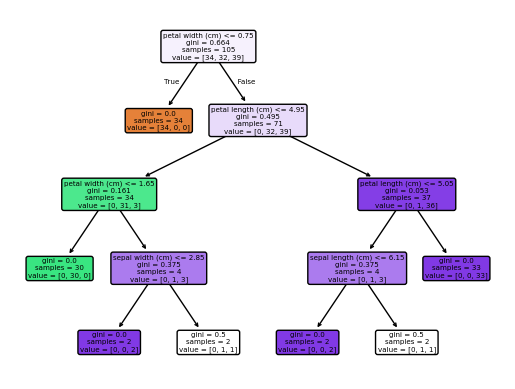

In [20]:
from sklearn.tree import plot_tree

X = pd.DataFrame(data['data'], columns = data['feature_names'])
y = data['target'].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state=0)




plot_tree(clf.best_estimator_, filled=True, rounded=True, feature_names=X_train.columns);

### Decision tree for regression

Dataset of house prices in California

In [78]:
from sklearn.datasets import fetch_openml

california = fetch_openml(name="california_housing", version=1, as_frame=True)
california_X = california.data
california_X = california_X.drop(columns=['ocean_proximity'])
california_Y = california.target.astype(float) / 100_000
print(f"X shape: {california_X.shape}, Y shape: {california_Y.shape}")
california_X.head()

X shape: (20640, 8), Y shape: (20640,)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
0,-122.23,37.88,41,880,129.0,322,126,8.3252
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014
2,-122.24,37.85,52,1467,190.0,496,177,7.2574
3,-122.25,37.85,52,1274,235.0,558,219,5.6431
4,-122.25,37.85,52,1627,280.0,565,259,3.8462


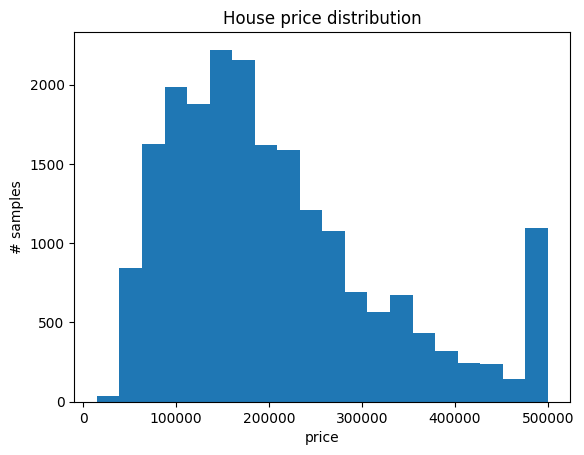

In [30]:
plt.title("House price distribution")
plt.xlabel("price")
plt.ylabel("# samples")
plt.hist(california_Y, bins=20)
plt.show()

[DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html) has similar hyperparameters, but the criterion is not Gini/entropy, but MSE

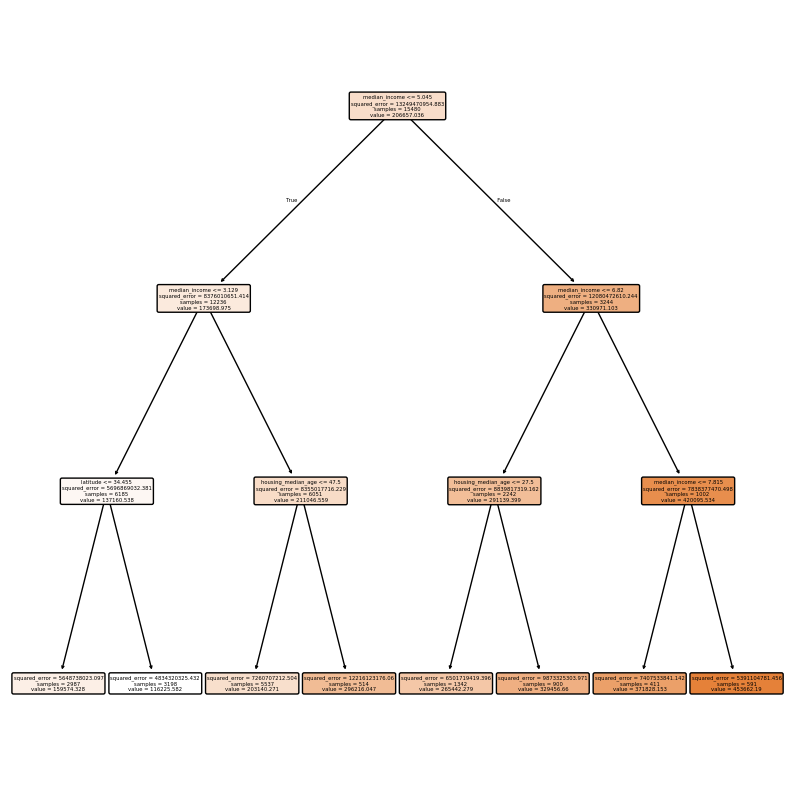

In [31]:
from sklearn.tree import DecisionTreeRegressor

X_train, X_test, y_train, y_test = train_test_split(
    california_X, california_Y, test_size=0.25, random_state=13
)

dt = DecisionTreeRegressor(max_depth=3, random_state=13)
dt.fit(X_train, y_train)

plt.figure(figsize=(10,10))
plot_tree(dt, feature_names=california_X.columns, filled=True, rounded=True)
plt.show()

Let's check how the result depend on the max depth of the tree

In [32]:
X_train.shape #May build deep trees

(15480, 8)

**Task** Fit a tree with every depth in `max_depth_array` array, compute and save MSE

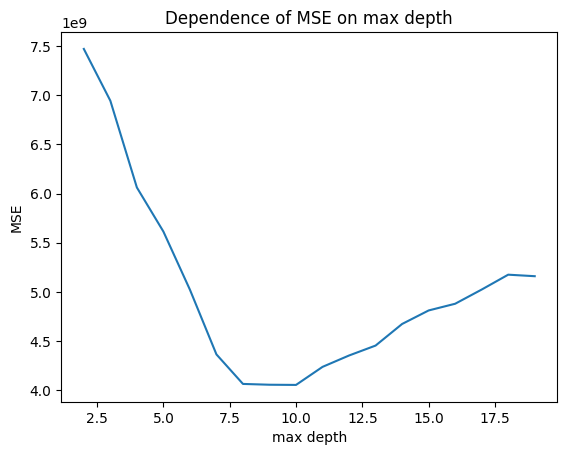

In [33]:
from sklearn.metrics import mean_squared_error
max_depth_array = range(2, 20)
mse_array = []

for max_depth in max_depth_array:
    dt = DecisionTreeRegressor(max_depth=max_depth).fit(X_train, y_train)
    mse = mean_squared_error(y_test, dt.predict(X_test))
    mse_array.append(mse)

plt.plot(max_depth_array, mse_array)
plt.title("Dependence of MSE on max depth")
plt.xlabel("max depth")
plt.ylabel("MSE");

**Task** Choose the depth with the best MSE

In [34]:
#your code here
max_depth_array[np.argmin(mse_array)]

10

**Task** Conduct same experiment with `min_samples_leaf`, use the best depth

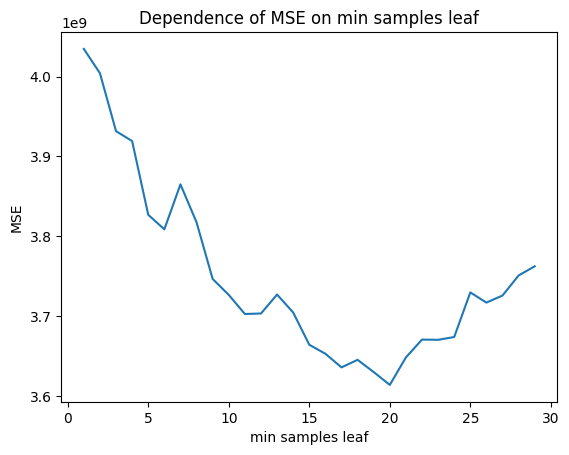

In [35]:
min_samples_leaf_array = range(1, 30)
mse_array = []

for min_samples_leaf in min_samples_leaf_array:
    dt = DecisionTreeRegressor(max_depth=10, min_samples_leaf=min_samples_leaf).fit(X_train, y_train)
    mse = mean_squared_error(y_test, dt.predict(X_test))
    mse_array.append(mse)

plt.plot(min_samples_leaf_array, mse_array)
plt.title("Dependence of MSE on min samples leaf")
plt.xlabel("min samples leaf")
plt.ylabel("MSE");

**Task** Choose the min samples leaf with the best MSE and fit the model again

In [36]:
#your code here
min_samples_leaf_array[np.argmin(mse_array)]

20

In [38]:
dt = DecisionTreeRegressor(max_depth=10,
                           min_samples_leaf=11,
                           random_state=13)
dt.fit(X_train, y_train)

mean_squared_error(y_test, dt.predict(X_test))

3704006261.21753

Let's use grid search to tune hyperparameters (Note: in the previous example we used test data to choose the best model, in reality we will use validation set)

It may take 2-5 minutes

In [39]:
dt_params = {
             'max_depth' : max_depth_array,
             'min_samples_leaf' : min_samples_leaf_array
             }

clf = GridSearchCV(DecisionTreeRegressor(), dt_params,
                   cv=3,
                   scoring='neg_root_mean_squared_error', #scoring for regression
                   verbose=5
                   )
clf.fit(X_train, y_train)
mean_squared_error(y_test, clf.predict(X_test))

Fitting 3 folds for each of 522 candidates, totalling 1566 fits
[CV 1/3] END max_depth=2, min_samples_leaf=1;, score=-84847.235 total time=   0.1s
[CV 2/3] END max_depth=2, min_samples_leaf=1;, score=-85561.007 total time=   0.1s
[CV 3/3] END max_depth=2, min_samples_leaf=1;, score=-87321.956 total time=   0.1s
[CV 1/3] END max_depth=2, min_samples_leaf=2;, score=-84847.235 total time=   0.1s
[CV 2/3] END max_depth=2, min_samples_leaf=2;, score=-85561.007 total time=   0.1s
[CV 3/3] END max_depth=2, min_samples_leaf=2;, score=-87321.956 total time=   0.1s
[CV 1/3] END max_depth=2, min_samples_leaf=3;, score=-84847.235 total time=   0.1s
[CV 2/3] END max_depth=2, min_samples_leaf=3;, score=-85561.007 total time=   0.0s
[CV 3/3] END max_depth=2, min_samples_leaf=3;, score=-87321.956 total time=   0.0s
[CV 1/3] END max_depth=2, min_samples_leaf=4;, score=-84847.235 total time=   0.0s
[CV 2/3] END max_depth=2, min_samples_leaf=4;, score=-85561.007 total time=   0.1s
[CV 3/3] END max_depth=

3566519264.3686576

In [40]:
clf.best_params_

{'max_depth': 13, 'min_samples_leaf': 16}

The result is better and the hyperparameters are different.

It is possible to measure feature importance (for classification and regression) - sklearn computes them for us.

In [41]:
pd.DataFrame(
    {"feature": california_X.columns, "importance": clf.best_estimator_.feature_importances_}
).sort_values(by="importance", ascending=False).reset_index(drop=True)

,feature,importance
0,median_income,0.581936
1,longitude,0.174574
2,latitude,0.155107
3,housing_median_age,0.058899
4,total_rooms,0.009940
5,population,0.008829
6,total_bedrooms,0.006439
7,households,0.004277


**Question** does scaling change anything?

**Task** Apply scaling and fit the model with same hyperparameters - what is different? (Feature importances? Error?)

In [42]:
from sklearn.preprocessing import StandardScaler

#Apply scaling

sc = StandardScaler()
X_train_scaled = pd.DataFrame(
    sc.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    sc.transform(X_test), columns=X_test.columns, index=X_test.index
)
X_train_scaled.head()

dt1 = DecisionTreeRegressor(random_state = 13,
                            max_depth =  14,
                            min_samples_leaf =  14
                            #your code here
                            )
#Fit model, compute MSE, depict importances
#your code here
dt1.fit(X_train_scaled, y_train)
(mean_squared_error(y_test, dt1.predict(X_test_scaled)))

3578759707.020171

In [43]:
pd.DataFrame(
    {"feature": california_X.columns, "importance": dt1.feature_importances_}
).sort_values(by="importance", ascending=False).reset_index(drop=True)

,feature,importance
0,median_income,0.574644
1,longitude,0.176484
2,latitude,0.157153
3,housing_median_age,0.060020
4,total_rooms,0.008827
5,population,0.008802
6,households,0.007503
7,total_bedrooms,0.006567


## Ensembles

### Bagging + Random Forest

Idea: generate new samples from our using bootstrap (samples are close enough, so the models wil extract similar real dependencies, but different enough to overfitted models to differ)

Let's work with some bigger dataset for regression

Let's fit a decision tree

In [56]:
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor()
tree.fit(X_train, y_train)


print(f"MSE on train set: {mean_squared_error(y_train, tree.predict(X_train)):.2f}")
print(f"MSE on test set: {mean_squared_error(y_test, tree.predict(X_test)):.2f}")

MSE on train set: 248490.31
MSE on test set: 5171386175.90


MSE on train data is 0.0, but on test data is larger. That seems like overfitting. (Decision tree without constraints can reach ideal quality on non-contradicting data.

Let's try to use bagging. First of all, let's implement bootstrap.

Idea: from our data choose random elements and get new sample with the same number of samples

In [57]:
def bootstrap(samples):
  idx = np.random.choice(len(samples), replace=True, size=len(samples))
  return samples[idx].copy()

In [58]:
bootstrap(np.array([1,2,3,4,5]))

array([3, 4, 3, 4, 2])

In [59]:
def generate_bootstrap(samples, N):
  bootstrap_samples = []
  for i in range(N):
    bootstrap_samples.append(bootstrap(samples))
  return np.array(bootstrap_samples)

In [60]:
generate_bootstrap(np.array([1,2,3,4,5]), 3)

array([[3, 1, 2, 2, 1],
       [2, 4, 4, 5, 5],
       [1, 2, 5, 1, 3]])

Let's generate several bootstrap samples and investigate features.

In [61]:
np.random.seed(0)
N = 8

#We need to merge X and y, because the same bootstrap should be applied to both X and y
X_y_train = X_train.copy()
X_y_train['y'] = y_train.copy()

bootstrap_samples = generate_bootstrap(X_y_train.values, N)
bootstrap_samples.shape

(8, 15480, 9)

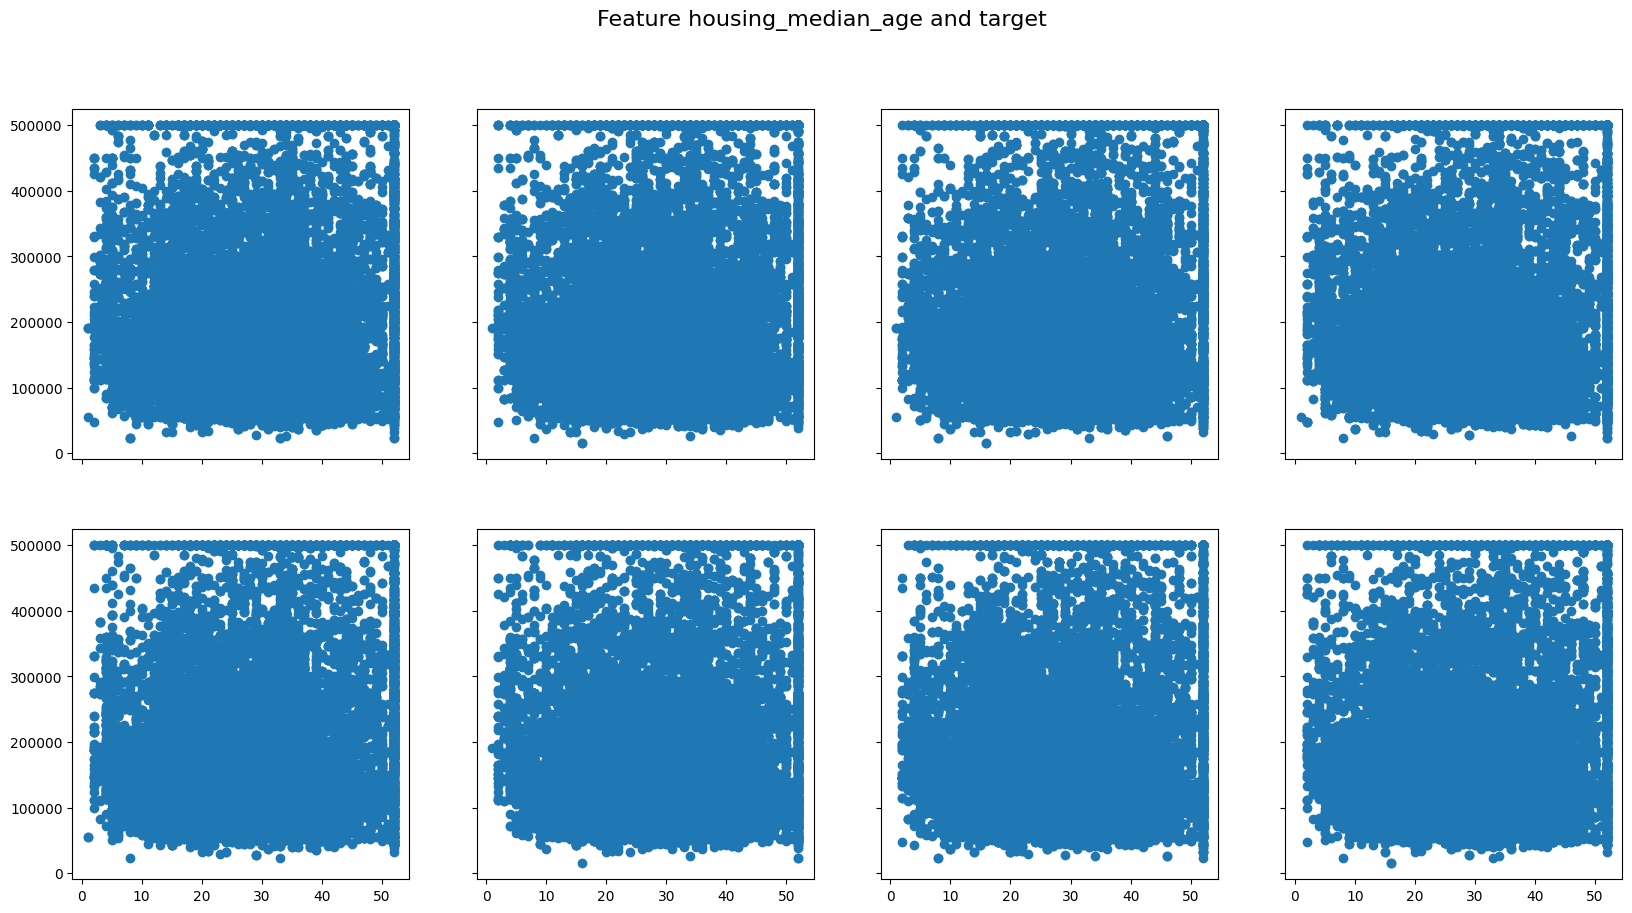

In [62]:
fig, axs = plt.subplots(ncols=N//2, nrows=2, figsize=(20,10), sharex=True, sharey=True)

feature = 2
for i in range(N):
  axs[i//4][i%4].scatter(bootstrap_samples[i][:,feature], bootstrap_samples[i][:,-1])

fig.suptitle('Feature ' + X_y_train.columns[feature] + ' and target', fontsize=16)
plt.show();

Now, let's fit separate decision tree with every sample we have

In [63]:
models = []

for sample in bootstrap_samples:
  tree = DecisionTreeRegressor(random_state=0)
  tree.fit(sample[:,:-1], sample[:,-1])
  models.append(tree)

In [64]:
models

[DecisionTreeRegressor(random_state=0),
 DecisionTreeRegressor(random_state=0),
 DecisionTreeRegressor(random_state=0),
 DecisionTreeRegressor(random_state=0),
 DecisionTreeRegressor(random_state=0),
 DecisionTreeRegressor(random_state=0),
 DecisionTreeRegressor(random_state=0),
 DecisionTreeRegressor(random_state=0)]

How does every tree perform?

In [65]:
for tree in models:
  print(f"MSE on test set: {mean_squared_error(y_test, tree.predict(X_test.values)):.3f}")

MSE on test set: 5505011274.889
MSE on test set: 5667024215.011
MSE on test set: 5047929532.643
MSE on test set: 5847788781.676
MSE on test set: 5879245380.084
MSE on test set: 5390146064.809
MSE on test set: 5303859267.988
MSE on test set: 5616072383.067


Now, let's take mean prediction for every sample

In [66]:
preds_trees = []
for tree in models:
  preds_trees.append(tree.predict(X_test.values))
preds_trees = np.array(preds_trees)

preds_trees.shape

(8, 5160)

In [67]:
mean_prediction = np.mean(preds_trees, axis=0)
mean_prediction.shape

(5160,)

In [68]:
mean_prediction

array([102100. , 204987.5,  92825. , ..., 232812.5,  69875. ,  60925. ],
      shape=(5160,))

In [69]:
print(f"MSE on test set: {mean_squared_error(y_test, mean_prediction):.2f}")

MSE on test set: 2941492597.91


The MSE on test  decreased! The bagging seems to be working

Let's now use the `BaggingRegressor` from sklearn. It will perform bootstrap, fit several models and take mean as prediction

In [70]:
from sklearn.ensemble import BaggingRegressor

base_tree = DecisionTreeRegressor(random_state=0)

#we will have 8 trees
bag = BaggingRegressor(base_tree,
                       n_estimators=8
                       )
bag.fit(X_train, y_train)


print(f"MSE on train set: {mean_squared_error(y_train, bag.predict(X_train)):.2f}")
print(f"MSE on test set: {mean_squared_error(y_test, bag.predict(X_test)):.2f}")

MSE on train set: 500968664.58
MSE on test set: 2971966800.20


MSE on train set increases, because not every tree is fitted to predict every sample, so particular overfitted trees may be wrong on train data. MSE on test set is better.

How many models should we take?

Let's fit bagging several times with different number of models

1
6
11
16
21


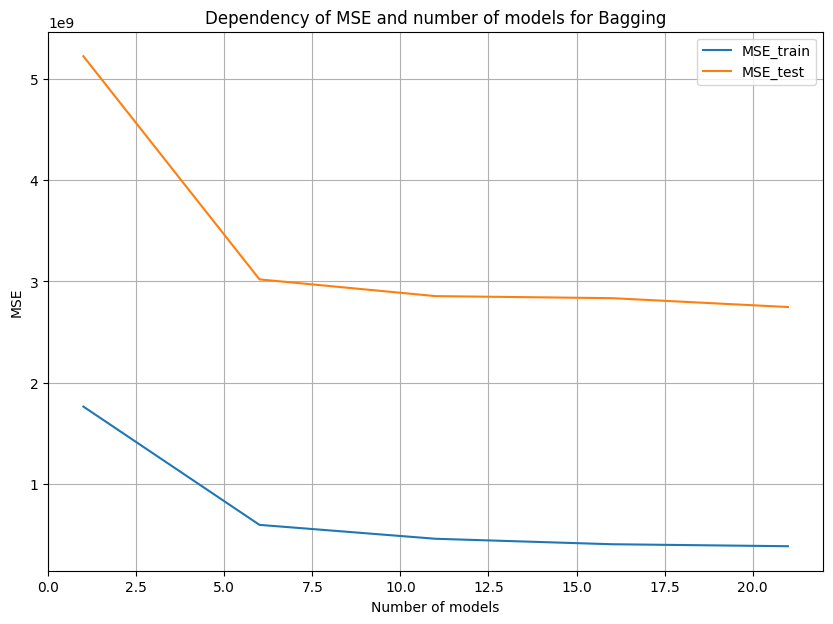

In [71]:
n_trees = range(1, 22, 5)
train_loss = []
test_loss = []

for i in n_trees:
    print(i)
    bagging = BaggingRegressor(base_tree,
                               n_estimators=i,
                               n_jobs=4

                       )
    bagging.fit(X_train, y_train)
    train_loss.append(mean_squared_error(y_train, bagging.predict(X_train)))
    test_loss.append(mean_squared_error(y_test, bagging.predict(X_test)))

plt.figure(figsize=(10, 7))
plt.title("Dependency of MSE and number of models for Bagging")
plt.grid()
plt.plot(n_trees, train_loss, label="MSE_train")
plt.plot(n_trees, test_loss, label="MSE_test")
plt.ylabel("MSE")
plt.xlabel("Number of models")
plt.legend();

When we had only 1 tree - MSE was big, we started adding trees and the error begin decreasing. However, after having ~20 trees it stopped decreasing and became almost constant.

Why? in the beginning every new tree brings useful information, new predictions, but after we added a lot of trees, next one will not be useful, it will be repeating the answers of previous one and the impact will be smaller.

### Random Forest

Bagging can be used with any base model (linear regression, decision tree).

Using trees is the most popular variant (they can learn non-linear dependencies, but easily overfit). It is possible to apply additional modification to make trees mode diverse - limit the number of features that can be used while spliting nodes in trees. Trees will still be able to discover complex dependencies, but they will significantly differ from each

In [72]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=8, n_jobs=4, max_features=0.5)
rf.fit(X_train, y_train)

print(f"MSE on train set: {mean_squared_error(y_train, rf.predict(X_train)):.4f}")
print(f"MSE on train set: {mean_squared_error(y_test, rf.predict(X_test)):.4f}")

MSE on train set: 554472189.1755
MSE on train set: 3040137185.2487


In [73]:
rf.max_features

0.5

The results are similar to the ones of bagging. Let's investigate number of trees:

1
6
11
16
21


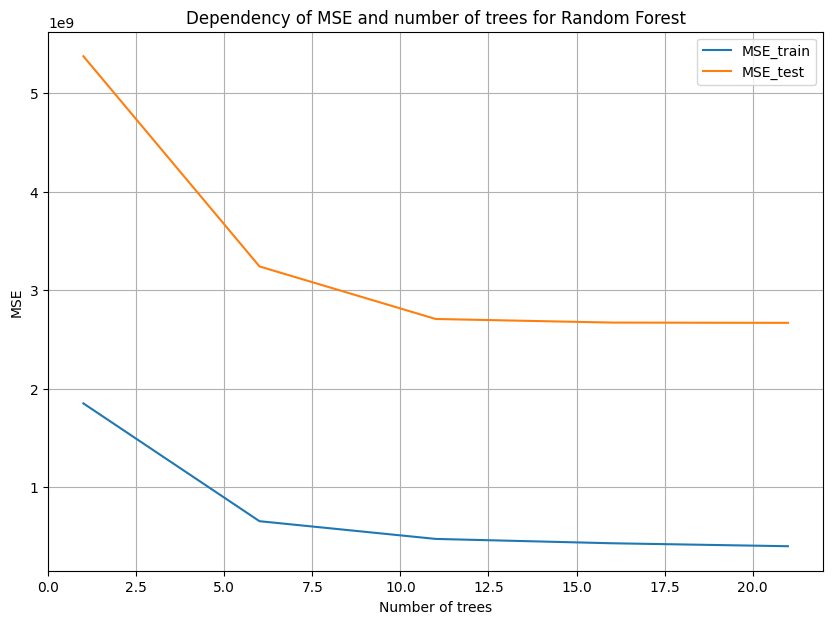

In [74]:
n_trees = range(1, 22, 5)
train_loss = []
test_loss = []

for i in n_trees:
    print(i)
    rf = RandomForestRegressor(n_estimators=i, n_jobs=4, max_features=0.5)
    rf.fit(X_train, y_train)
    train_loss.append(mean_squared_error(y_train, rf.predict(X_train)))
    test_loss.append(mean_squared_error(y_test, rf.predict(X_test)))

plt.figure(figsize=(10, 7))
plt.title("Dependency of MSE and number of trees for Random Forest")
plt.grid()
plt.plot(n_trees, train_loss, label="MSE_train")
plt.plot(n_trees, test_loss, label="MSE_test")
plt.ylabel("MSE")
plt.xlabel("Number of trees")
plt.legend();

### Boosting

Idea: we fitted one model and it made some mistekes, let's teach the next model to fix them.

Example: the item costed 15 rub., model 1 predicted that the item will cost 25rub.. So the  model 2 should try to predict 15rub. - 25rub. = -10rub..

Predictions of model 2 cannot be used without predictions of model 1 (item cannot cost -10rub.), so, we will need to sum the predictions to get the final prediction: 25rub. + (-10rub.) = 15rub.


$$a(x) = \sum_{n=1}^N b_n(x)$$

$a(x)$ - the prediction of the ensemble

$b_n(x)$ - the prediction of the $n$-th base model

Model 1 and 2 (base models) are usually trees, but significantly underfitted (not deep, not many leaves, a lot of samples in each leaf). That prevents the overfitting of boosting (if an overfitted model will be fixing the mistakes of overfitted model, the ensemble will be significantly overfitted)

### Decision tree vs gradient boosting on California Housing

Let's compare both models on the same train and test sets using MSE.

In [77]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer

X_train, X_test, y_train, y_test = train_test_split(
    california_X, california_Y, test_size=0.25, random_state=13
)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

forest = RandomForestRegressor(n_estimators=8, max_features=0.5, random_state=13)
boosting = GradientBoostingRegressor(n_estimators=1000, random_state=13)

for name, model in [("Random forest", forest), ("Gradient boosting", boosting)]:
    model.fit(X_train, y_train)
    print(name)
    print(f"MSE on train set: {mean_squared_error(y_train, model.predict(X_train)):.3f}")
    print(f"MSE on test set:  {mean_squared_error(y_test, model.predict(X_test)):.3f}")

Random forest
MSE on train set: 496949077.859
MSE on test set:  2848665669.394
Gradient boosting
MSE on train set: 1352363573.272
MSE on test set:  2351804798.183
